In [8]:
import plot_func
from plot_func import plot_results
import matplotlib.pyplot as plt

from importlib import reload
import os
reload(plot_func)

model_name = "model_4.2"
os.makedirs(f'..\\Figures\\{model_name}', exist_ok=True)

axial force top of pile: -2070.7939257579974 kN
moment top of pile: -1633.405533585806 kNm
Expected Moment: N * 0.71 = -1470.263687288178 kNm


max displacement: 56.84445517643911 mm
max measured displacement: 53.76643396441688 mm
top displacement: 36.18460105719298 mm
top measured displacement: 16.95413164983686 mm


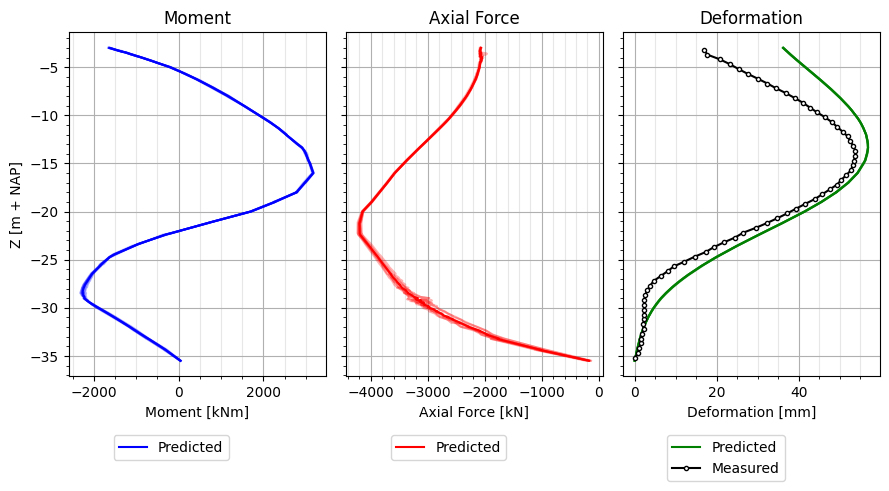

In [10]:
# date_strains = ['28-11-2025 08:46', '28-11-2025 08:43']
date_strains = ['03-10-2025 09:45', '03-10-2025 09:42']
# date_inclino = '03-10-2025 09:39:51'

date_strains = None
date_inclino = '17-06-2026 12:54:29'

path_plaxis = f'..\\Data\\Initial_Model_Predictions\\{model_name}'
phase_1 = 10
phase_0 = 4
# os.makedirs(f'..\\Figures\\{model_name}\\phase_{phase_0}_to_{phase_1}', exist_ok=True)
path_strains = '..\\Data\\Measurements\\Strains'
path_inclino = '..\\Data\\Measurements'

dF_PLAXIS, df_strain, df_inclino = plot_results(phase_1, 'BP', path_plaxis, path_strains, path_inclino, date_strains, date_inclino, 
                                                section=['84', '68'], section_inclino=['76'], 
                                                phase_0=phase_0, model_name=model_name)

print(f"axial force top of pile: {dF_PLAXIS['N_avg'].iloc[-1]} kN")
print(f"moment top of pile: {dF_PLAXIS['M_avg'].iloc[-1]} kNm")
print(f"Expected Moment: N * 0.71 = {dF_PLAXIS['N_avg'].iloc[-1] * 0.71} kNm")
print()
if date_strains:
      print(f"measured axial force top of pile: {df_strain['N_strain_sc68'].dropna().iloc[-1]:.2f} kN (sc68),\
            {df_strain['N_strain_sc84'].iloc[-1]:.2f} kN (sc84)")
      print(f"measured moment top of pile: {df_strain['M_strain_sc68'].dropna().iloc[-1]:.2f} kNm (sc68), {df_strain['M_strain_sc84'].iloc[-1]:.2f} kNm (sc84)")
      print(f"Expected Moment: N * 0.71 = {df_strain['N_strain_sc68'].dropna().iloc[-1] * 0.71:.2f} kNm (sc68),{df_strain['N_strain_sc84'].iloc[-1] * 0.71:.2f} kNm (sc84)")



print()
print(f"max displacement: {dF_PLAXIS['U_avg'].max()} mm")
print(f"max measured displacement: {df_inclino['U_inclino_sc76'].max()} mm")

print(f"top displacement: {dF_PLAXIS['U_avg'].iloc[-1]} mm")
print(f"top measured displacement: {df_inclino['U_inclino_sc76'].iloc[-1]} mm")

,M_avg,N_avg,U_avg
Z,,,
-35.500000,43.179888,-172.443409,0.000000
-34.366514,-311.122953,-1034.162961,0.588186
-34.354769,-312.761492,-1026.389865,0.595680
-33.233029,-714.148600,-1776.001371,1.248767
-33.221283,-719.578137,-1767.238710,1.259056
...,...,...,...
-3.337018,-1371.820231,-2081.886656,37.030353
-3.299874,-1401.235283,-2084.717340,36.937328
-3.280099,-1423.194294,-2084.160814,36.888841


C:\Users\max\AppData\Local\Temp\ipykernel_21128\1622352923.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend()


(-35.5, -2.0)

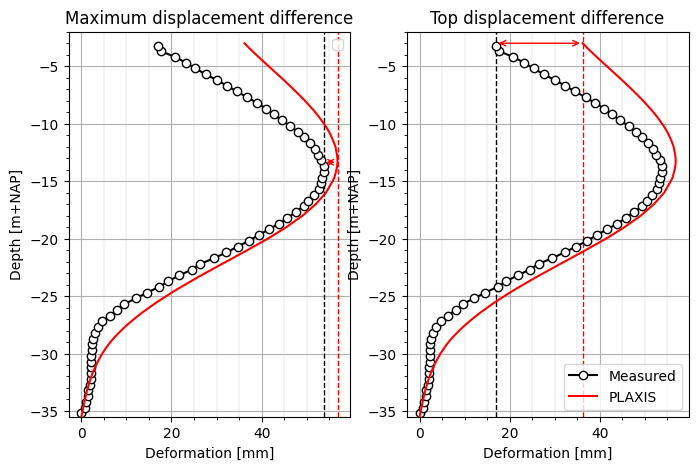

In [12]:
display(dF_PLAXIS)

u_max_pred = dF_PLAXIS['U_avg'].max()
u_max_meas = df_inclino['U_inclino_sc76'].max()
z_maxdeform = dF_PLAXIS['U_avg'].idxmax()
# display(u_max_pred, u_max_meas)
# display(u_top_pred, u_top_meas)

ymin = dF_PLAXIS.index.min()
ymax = dF_PLAXIS.index.max() + 1

fig, ax = plt.subplots(1, 2, figsize = (8,5))
# ax[0].vlines(u_max_pred, ymin=ymin, ymax=ymax, 
#           colors='r', linestyles='dashed', label=f'Max Predicted: {u_max_pred:.1f} mm', linewidth=1)
# ax[0].vlines(u_max_meas, ymin=ymin, ymax=ymax, 
#           colors='k', linestyles='dashed', label=f'Max Measured: {u_max_meas:.1f} mm', linewidth=1)
ax[0].vlines(u_max_pred, ymin=ymin, ymax=ymax, 
          colors='r', linestyles='dashed', linewidth=1)
ax[0].vlines(u_max_meas, ymin=ymin, ymax=ymax, 
          colors='k', linestyles='dashed', linewidth=1)
ax[0].annotate('', xy=(u_max_pred, z_maxdeform), xytext=(u_max_meas, z_maxdeform),
             arrowprops=dict(arrowstyle='<->', color='r'))
ax[0].plot(df_inclino['U_inclino_sc76'], df_inclino.index, marker='o', markerfacecolor='white', color = 'k')
ax[0].plot(dF_PLAXIS['U_avg'], dF_PLAXIS.index, color = 'r')

ax[0].set_xlabel('Deformation [mm]')
ax[0].set_ylabel('Depth [m+NAP]')
ax[0].legend()
ax[0].minorticks_on()
ax[0].grid(which = 'major', axis='both')
ax[0].grid(which = 'minor', axis='x', linewidth = 0.2)
ax[0].set_title('Maximum displacement difference')
ax[0].set_ylim(ymin, ymax)

u_top_pred = dF_PLAXIS['U_avg'].iloc[-1]
u_top_meas = df_inclino['U_inclino_sc76'].iloc[-1]

z_topdeform = -3

# ax[1].vlines(u_top_pred, ymin=ymin, ymax=ymax, 
#           colors='r', linestyles='dashed', label=f'Top predicted: {u_top_pred:.1f} mm', linewidth=1)
ax[1].vlines(u_top_pred, ymin=ymin, ymax=ymax, 
          colors='r', linestyles='dashed', linewidth=1)
# ax[1].vlines(u_top_meas, ymin=ymin, ymax=ymax, 
#           colors='k', linestyles='dashed', label=f'Top measured: {u_top_meas:.1f} mm', linewidth=1)
ax[1].vlines(u_top_meas, ymin=ymin, ymax=ymax, 
          colors='k', linestyles='dashed', linewidth=1)
ax[1].plot(df_inclino['U_inclino_sc76'], df_inclino.index, label='Measured', marker='o', markerfacecolor='white', color = 'k')
ax[1].plot(dF_PLAXIS['U_avg'], dF_PLAXIS.index, label='PLAXIS', color = 'r')
ax[1].annotate('', xy=(u_top_pred, z_topdeform), xytext=(u_top_meas, z_topdeform),
             arrowprops=dict(arrowstyle='<->', color='r'))


ax[1].set_xlabel('Deformation [mm]')
ax[1].set_ylabel('Depth [m+NAP]')
ax[1].legend()
ax[1].minorticks_on()
ax[1].grid(which = 'major', axis='both')
ax[1].grid(which = 'minor', axis='x', linewidth = 0.2)
ax[1].set_title('Top displacement difference')
ax[1].set_ylim(ymin, ymax)

# for ax_i in ax:
#     ax_i.set_xticks([])
#     ax_i.set_yticks([])
#     ax_i.spines['top'].set_visible(False)
#     ax_i.spines['right'].set_visible(False)
#     ax_i.spines['bottom'].set_visible(False)
#     ax_i.spines['left'].set_visible(False)
#     ax_i.set_xlabel('')
#     ax_i.set_ylabel('')

# fig.suptitle('Predicted vs measured displacement For final dredgin phase 8')

